# Quick Start: Iterating over splits of gift-eval datasets
First lets check the names of all the datasets in the `gift-eval` directory.

Make sure you download the gift-eval benchmark and set the `GIFT-EVAL` environment variable correctly before running this notebook.



In [1]:
%matplotlib inline
import os
import math
from numpy import linalg as LA
from dotenv import load_dotenv
from pathlib import Path

import numpy as np
import sys

sys.path.append(str(Path.cwd().parent))

from gift_eval.data import Dataset
from src import KMD_lib
import importlib
importlib.reload(KMD_lib)


# Load environment variables
load_dotenv()

os.environ["GIFT_EVAL"] = "/Users/jonghyeonlee/KMD_TS/GiftEval_data"

# Get the GIFT_EVAL path from environment variables
gift_eval_path = os.getenv("GIFT_EVAL")

if gift_eval_path:
    # Convert to Path object for easier manipulation
    gift_eval_path = Path(gift_eval_path)

    # Get all subdirectories (dataset names) in the GIFT_EVAL path
    dataset_names = []
    for dataset_dir in gift_eval_path.iterdir():
        if dataset_dir.name.startswith("."):
            continue
        if dataset_dir.is_dir():
            freq_dirs = [d for d in dataset_dir.iterdir() if d.is_dir()]
            if freq_dirs:
                for freq_dir in freq_dirs:
                    dataset_names.append(f"{dataset_dir.name}/{freq_dir.name}")
            else:
                dataset_names.append(dataset_dir.name)

    print("Available datasets in GIFT_EVAL:")
    for name in sorted(dataset_names):
        print(f"- {name}")
else:
    print(
        "GIFT_EVAL path not found in environment variables. Please check your .env file."
    )

/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/gluonts/json.py:102: UserWarning: Using `json`-module for json-handling. Consider installing one of `orjson`, `ujson` to speed up serialization and deserialization.
  warnings.warn(


Available datasets in GIFT_EVAL:
- LOOP_SEATTLE/5T
- LOOP_SEATTLE/D
- LOOP_SEATTLE/H
- M_DENSE/D
- M_DENSE/H
- SZ_TAXI/15T
- SZ_TAXI/H
- bitbrains_fast_storage/5T
- bitbrains_fast_storage/H
- bitbrains_rnd/5T
- bitbrains_rnd/H
- bizitobs_application
- bizitobs_l2c/5T
- bizitobs_l2c/H
- bizitobs_service
- car_parts_with_missing
- covid_deaths
- electricity/15T
- electricity/D
- electricity/H
- electricity/W
- ett1/15T
- ett1/D
- ett1/H
- ett1/W
- ett2/15T
- ett2/D
- ett2/H
- ett2/W
- hierarchical_sales/D
- hierarchical_sales/W
- hospital
- jena_weather/10T
- jena_weather/D
- jena_weather/H
- kdd_cup_2018_with_missing/D
- kdd_cup_2018_with_missing/H
- m4_daily
- m4_hourly
- m4_monthly
- m4_quarterly
- m4_weekly
- m4_yearly
- restaurant
- saugeenday/D
- saugeenday/M
- saugeenday/W
- solar/10T
- solar/D
- solar/H
- solar/W
- temperature_rain_with_missing
- us_births/D
- us_births/M
- us_births/W


# Loading Datasets

We provide a simple class, called `Dataset`, to load each dataset in our benchmark following the gluonts interface. It is highly recommended to use this class to split the data to train/val/test for compatibility with the evaluation framework and other baselines in the leaderboard. You don't have to stick to gluonts interface though as you can easily implement a wrapper class to load the data iterator in a different format than gluonts.

This class provides the following properties:

- `training_dataset`: The training dataset.
- `validation_dataset`: The validation dataset.
- `test_data`: The test dataset.

Note that timeseries modality splits the data to train/val/test on the time dimension rather than the series dimension. Thus each of these splits utilize same series but different time indices. The number of windows for rolling evaluation is determined by the `Dataset` class. 

The training_dataset and validation_dataset are iterators where each element is a dictionary with the following keys:

- `start`: the start time of the window
- `target`: the target values of the window
- `item_id`: the id of the series
- `freq`: The frequency of the series
- `past_feat_dynamic_real`: [If exists] the past feature dynamic real values of the window


The test_data is a tuple with two dictionaries. First for the context, second for the forecast horizon, where each dictionary contains the same keys as above.


## Example Usage: SZ_TAXI/15T

Lets load and inspect the SZ_TAXI/15T dataset using our `Dataset` class.

In [2]:
from gluonts.dataset.util import to_pandas
import matplotlib.pyplot as plt

ds_name = "SZ_TAXI/15T"  # Name of the dataset
to_univariate = False  # Whether to convert the data to univariate
term = "short"  # Term of the dataset

dataset = Dataset(name=ds_name, term=term, to_univariate=to_univariate)
print("Dataset frequency: ", dataset.freq)
print("Prediction length: ", dataset.prediction_length)
print("Number of windows in the rolling evaluation: ", dataset.windows)

Dataset frequency:  15T
Prediction length:  48
Number of windows in the rolling evaluation:  7


/Users/jonghyeonlee/KMD_TS/gift_eval/data.py:151: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  freq = norm_freq_str(to_offset(self.freq).name)


Keys in the training data:  dict_keys(['item_id', 'start', 'freq', 'target'])
Item id:  90217
Start Date:  2015-01-01 00:00
Frequency:  15T
Last 10 target values:  [30.794895 36.32789  33.58315  29.980373 32.072258 30.934692 40.101315
 39.35496  38.612152 35.180397]


/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/gluonts/dataset/common.py:263: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  return pd.Period(val, freq)


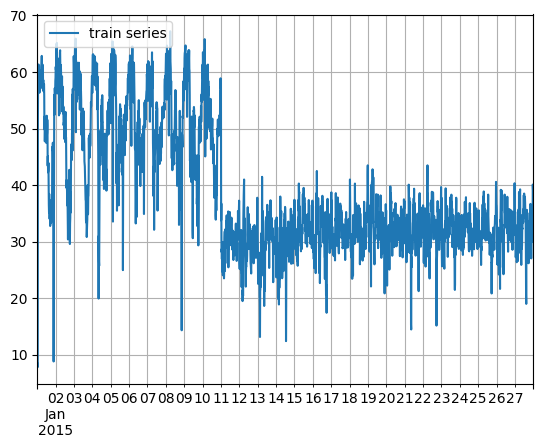

In [3]:
train_data_iter = dataset.training_dataset  # Get the training data iterator

train_data = next(iter(train_data_iter))
print("Keys in the training data: ", train_data.keys())

print("Item id: ", train_data["item_id"])
print("Start Date: ", train_data["start"])
print("Frequency: ", train_data["freq"])
print("Last 10 target values: ", train_data["target"][-10:])


train_series = to_pandas(train_data)
train_series.plot()
plt.grid(which="both")
plt.legend(["train series"], loc="upper left")
plt.show()

In [4]:
signal = train_data['target']
T_len = len(signal)
print(T_len)

2592


Energy computation progress:
0% 8 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=20, tm_min=58, tm_sec=11, tm_wday=0, tm_yday=103, tm_isdst=1)
4% 8 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=20, tm_min=58, tm_sec=11, tm_wday=0, tm_yday=103, tm_isdst=1)
8% 8 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=20, tm_min=58, tm_sec=11, tm_wday=0, tm_yday=103, tm_isdst=1)
12% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=20, tm_min=58, tm_sec=11, tm_wday=0, tm_yday=103, tm_isdst=1)
15% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=20, tm_min=58, tm_sec=11, tm_wday=0, tm_yday=103, tm_isdst=1)
19% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=20, tm_min=58, tm_sec=11, tm_wday=0, tm_yday=103, tm_isdst=1)
23% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=20, tm_min=58, tm_sec=11, tm_wday=0, tm_yday=103, tm_isdst=1)
27% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=20, 

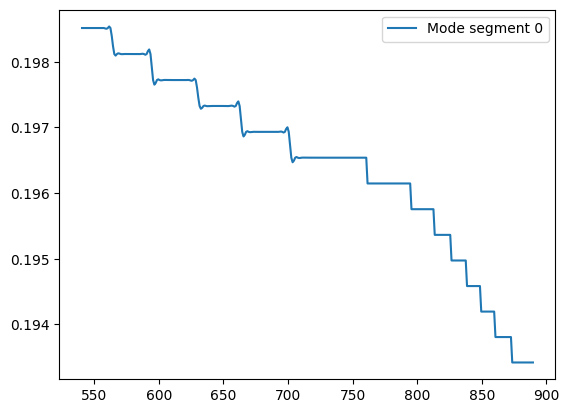

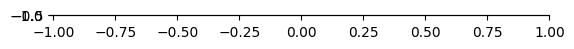

remaining_modes = [0]
You entered: 0
Allowed: [np.int64(0)]
Membership test: True
remaining_modes = []
mode_out.shape = (1, 2592, 4)
2000 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=20, tm_min=58, tm_sec=20, tm_wday=0, tm_yday=103, tm_isdst=1)
[[ 1.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00]
 [ 6.87142159e-01 -3.48219738e-02]
 [ 0.00000000e+00  0.00000000e+00]
 [ 5.63658409e-01 -8.54434175e-02]
 [ 5.90279274e-01 -6.16090049e-02]
 [ 5.62007982e-01  3.96479224e-03]
 [ 6.26408110e-01  0.00000000e+00]
 [ 0.00000000e+00  6.09250196e-02]
 [ 0.00000000e+00 -1.03172889e-02]
 [ 5.65489525e-01 -6.27756544e-02]
 [ 5.11631964e-01 -4.81423666e-02]
 [ 6.11616865e-01 -4.60892020e-02]
 [ 5.41086355e-01  4.29240264e-04]]
fmodes.shape = (1, 2592, 4)
fmodes[ 0 ].shape = (2592, 4)
mode 0 raw shape = (2592, 4)
Opt Final progress:
0
False
5
10
1000 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=20, tm_min=58, tm_sec=22, t

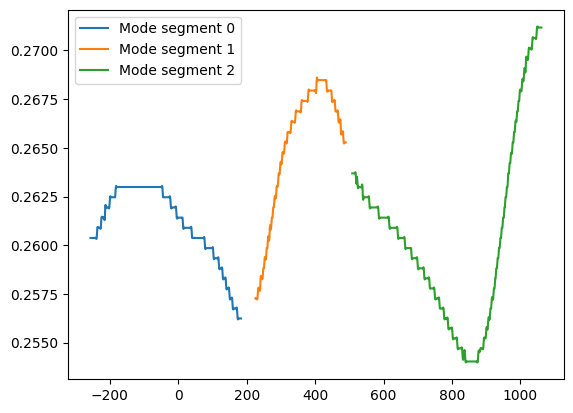

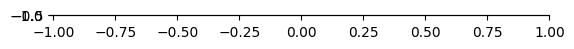

remaining_modes = [0 1 2]
You entered: 0
Allowed: [np.int64(0), np.int64(1), np.int64(2)]
Membership test: True
remaining_modes = [1 2]
You entered: 1
Allowed: [np.int64(1), np.int64(2)]
Membership test: True
remaining_modes = [2]
You entered: 2
Allowed: [np.int64(2)]
Membership test: True
remaining_modes = []
mode_out.shape = (1, 2592, 4)
2000 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=20, tm_min=59, tm_sec=1, tm_wday=0, tm_yday=103, tm_isdst=1)
[[1. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]]
fmodes.shape = (2, 2592, 4)
fmodes[ 0 ].shape = (2592, 4)
fmodes[ 1 ].shape = (2592, 4)
mode 0 raw shape = (2592, 4)
mode 1 raw shape = (2592, 4)
Opt Final progress:
0
False
5
10
0 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=20, tm_min=59, tm_sec=3, tm_wday=0, tm_yday=103, tm_isdst=1)
1000 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=20, tm_min=59, tm_sec=5, t

In [5]:
t_mesh = np.arange(T_len, dtype=float)
wave_params = ['unk',15]
alpha = 25.0

Comp_data_full, wp = KMD_lib.semimanual_maxpool_peel2(signal, wave_params, alpha, t_mesh, 0.003, 0.1, ref_fin=False)


In [6]:
Comp_data_full.shape

(2, 2592, 4)

In [7]:
import torch

def make_waveform_fn(coeffs):
    coeffs = torch.as_tensor(coeffs)

    def y(x):
        x = torch.as_tensor(x, dtype=coeffs.dtype, device=coeffs.device)
        out = torch.zeros_like(x)

        for k in range(coeffs.shape[0]):
            n = k + 1
            out = out + coeffs[k, 0] * torch.cos(n * x)
            if k > 0:
                out = out + coeffs[k, 1] * torch.sin(n * x)
        return out

    return y

In [8]:
def make_one_step_data(x, L=3):
    X, y = [], []
    for i in range(len(x) - L):
        X.append(x[i:i+L])
        y.append(x[i+L])
    return torch.stack(X), torch.stack(y)

def pairwise_sqdist(X1, X2):
    x1_norm = (X1**2).sum(dim=1, keepdim=True)
    x2_norm = (X2**2).sum(dim=1, keepdim=True).T
    return x1_norm + x2_norm - 2 * (X1 @ X2.T)

def gaussian_gram(X1, X2, ell):
    D2 = pairwise_sqdist(X1, X2)
    return torch.exp(-D2 / (2 * ell**2))

def median_lengthscale(X, max_points=2000):
    if len(X) > max_points:
        idx = torch.randperm(len(X))[:max_points]
        Xs = X[idx]
    else:
        Xs = X
    D2 = pairwise_sqdist(Xs, Xs)
    D = torch.sqrt(torch.clamp(D2, min=0.0))
    vals = D[torch.triu(torch.ones_like(D, dtype=torch.bool), diagonal=1)]
    vals = vals[vals > 0]
    if len(vals) == 0:
        return 1.0
    return torch.median(vals).item()

class KernelRepresenterForecaster:
    def __init__(self, L=3, ell=None, lam=1e-4, standardize=True):
        self.L = L
        self.ell = ell
        self.lam = lam
        self.standardize = standardize

        self.x_mean = None
        self.x_std = None
        self.X_train = None
        self.alpha = None

    def fit(self, x):
        X_train, y_train = make_one_step_data(x, L=self.L)

        if self.standardize:
            self.x_mean = x.mean()
            self.x_std = x.std()
            if self.x_std < 1e-8:
                self.x_std = torch.tensor(1.0, dtype=x.dtype, device=x.device)
            X_train = (X_train - self.x_mean) / self.x_std
            y_train = (y_train - self.x_mean) / self.x_std
        else:
            self.x_mean = torch.tensor(0.0, dtype=x.dtype, device=x.device)
            self.x_std = torch.tensor(1.0, dtype=x.dtype, device=x.device)

        if self.ell is None:
            self.ell = median_lengthscale(X_train)

        K = gaussian_gram(X_train, X_train, self.ell)
        n = len(X_train)
        K_reg = K + self.lam * torch.eye(n, dtype=K.dtype, device=K.device)

        self.X_train = X_train
        self.alpha = torch.linalg.solve(K_reg, y_train)

    def predict_next(self, x_window):
        xq = x_window.clone()
        if self.standardize:
            xq = (xq - self.x_mean) / self.x_std

        kq = gaussian_gram(xq.unsqueeze(0), self.X_train, self.ell).squeeze(0)
        yq = torch.dot(kq, self.alpha)

        if self.standardize:
            yq = yq * self.x_std + self.x_mean
        return yq

    def recursive_forecast(self, x_history, horizon_steps):
        history = x_history.clone()
        preds = []
        for _ in range(horizon_steps):
            x_window = history[-self.L:] 
            y_next = self.predict_next(x_window)
            preds.append(y_next)
            history = torch.cat([history, y_next.view(1)])
        return torch.stack(preds)

Keys in the validation data:  dict_keys(['item_id', 'start', 'freq', 'target'])
Item id:  90217
Start Date:  2015-01-01 00:00
Frequency:  15T
Last 10 target values:  [29.379454 32.326954 31.160337 29.345852 34.919918 32.35511  32.892193
 36.244965 36.604492 36.14439 ]


ConversionError: Failed to convert value(s) to axis units: [Period('2015-01-27 23:45', '15min'), Period('2015-01-27 23:45', '15min')]

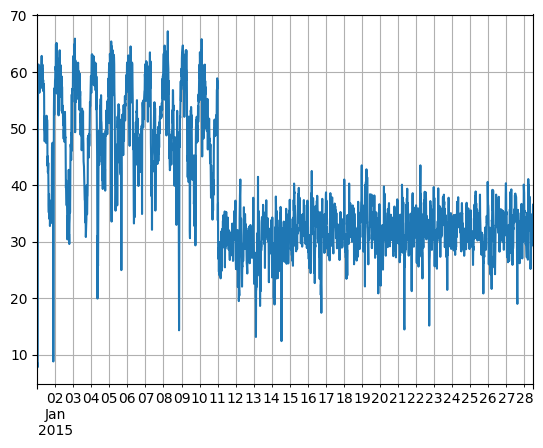

In [27]:
val_data_iter = dataset.validation_dataset

val_data = next(iter(val_data_iter))
print("Keys in the validation data: ", val_data.keys())

print("Item id: ", val_data["item_id"])
print("Start Date: ", val_data["start"])
print("Frequency: ", val_data["freq"])
print("Last 10 target values: ", val_data["target"][-10:])

val_series = to_pandas(val_data)
val_series.plot()
plt.grid(which="both")
# Add a vertical axis for where the train series ends
plt.axvline(
    x=train_series.index[-1], color="r", linestyle="--", label="End of train series"
)
plt.legend(["val series", "end of train series"], loc="upper left")
plt.show()

Keys in the test data:  dict_keys(['item_id', 'start', 'freq', 'target'])


Context Item id:  90217
Context Start Date:  2015-01-01 00:00
Context Frequency:  15T
Context Last 10 target values:  [29.379454 32.326954 31.160337 29.345852 34.919918 32.35511  32.892193
 36.244965 36.604492 36.14439 ]


Forecast Item id:  90217
Forecast Start Date:  2015-01-28 12:00
Forecast Frequency:  15T
Forecast Last 10 target values:  [30.04794  32.065666 33.79063  32.988396 26.592009 29.08736  34.313152
 36.92213  37.11307  40.779465]


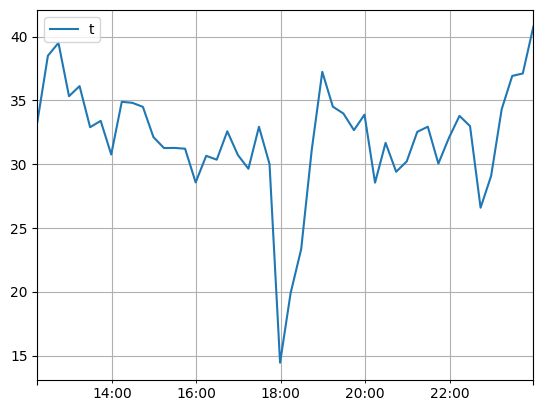

In [21]:
test_split_iter = dataset.test_data
test_data = next(iter(test_split_iter))

test_input_split_iter = dataset.test_data.input

input = next(iter(test_input_split_iter))
print("Keys in the test data: ", input.keys())

print("\n\nContext Item id: ", input["item_id"])
print("Context Start Date: ", input["start"])
print("Context Frequency: ", input["freq"])
print("Context Last 10 target values: ", input["target"][-10:])

test_label_split_iter = dataset.test_data.label
label = input = next(iter(test_label_split_iter))
print("\n\nForecast Item id: ", label["item_id"])
print("Forecast Start Date: ", label["start"])
print("Forecast Frequency: ", label["freq"])
print("Forecast Last 10 target values: ", label["target"][-10:])

test_series = to_pandas(test_data[1])
test_series.plot()
plt.grid(which="both")
plt.legend("test series", loc="upper left")
plt.show()

In [44]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

def rmse(pred, true):
    return torch.sqrt(torch.mean((pred - true)**2))

def mae(pred, true):
    return torch.mean(torch.abs(pred - true))

v = torch.Tensor(signal)
n_train = len(v)

v_train = v[:n_train]

full_data = torch.Tensor(Comp_data_full)

a1_train = full_data[0,:n_train,0]
a2_train = full_data[1,:n_train,0]
# a3_train = full_data[2,:n_train,0]
# a4_train = full_data[3,:n_train,0]
# a5_train = full_data[4,:n_train,0]


theta1_train = full_data[0,:n_train,1]
theta2_train = full_data[1,:n_train,1]
# theta3_train = full_data[2,:n_train,1]
# theta4_train = full_data[3,:n_train,1]
# theta5_train = full_data[4,:n_train,1]


omega1_train = full_data[0,:n_train,2]
omega2_train = full_data[1,:n_train,2]
# omega3_train = full_data[2,:n_train,2]
# omega4_train = full_data[3,:n_train,2]
# omega5_train = full_data[4,:n_train,2]

v_train = v[:n_train]

L_a = 20
L_omega = 10


In [45]:
v_train.shape

torch.Size([2592])

In [59]:
def rmse(x, y):
    return torch.sqrt(torch.mean((x - y)**2))

L = 20
horizon_steps = len(val_data["target"][n_train:])

model_v = KernelRepresenterForecaster(L=L, ell=None, lam=1e-4, standardize=True)
model_v.fit(v_train)
pred_from_v = model_v.recursive_forecast(v_train, horizon_steps)


model_a = KernelRepresenterForecaster(L=L_a, ell=None, lam=1e-4, standardize=True)


model_a.fit(a1_train)
model_a.fit(a2_train)

a1_pred = model_a.recursive_forecast(a1_train, horizon_steps)
a2_pred = model_a.recursive_forecast(a2_train, horizon_steps)


# 3) use true v1, v2 separately and sum
model_omega = KernelRepresenterForecaster(L=L_omega, ell=None, lam=1e-4, standardize=True)

model_omega.fit(omega1_train)
model_omega.fit(omega2_train)


omega1_pred = model_omega.recursive_forecast(omega1_train, horizon_steps)
omega2_pred = model_omega.recursive_forecast(omega2_train, horizon_steps)


theta1_pred = torch.zeros(horizon_steps)
theta2_pred = torch.zeros(horizon_steps)


ss = t_mesh[1]-t_mesh[0]

theta1_pred[0] = theta1_train[-1]+ss*omega1_train[-1]
theta2_pred[0] = theta2_train[-1]+ss*omega2_train[-1]


for i in range(1,horizon_steps):
    theta1_pred[i] = theta1_pred[i-1]+ss*omega1_pred[i-1]
    theta2_pred[i] = theta2_pred[i-1]+ss*omega2_pred[i-1]


w1_train = full_data[0,:,0] * make_waveform_fn(wp.f[0])(full_data[0,:,1])
w2_train = full_data[1,:,0] * make_waveform_fn(wp.f[0])(full_data[1,:,1])

model_w = KernelRepresenterForecaster(L=L, ell=None, lam=1e-4, standardize=True)

model_w.fit(w1_train)
model_w.fit(w2_train)

w1_pred = model_w.recursive_forecast(w1_train, horizon_steps)
w2_pred = model_w.recursive_forecast(w2_train, horizon_steps)


In [ ]:
w1_train

tensor([-2.0118, -2.0896, -2.1328,  ...,  0.0000,  0.0000,  0.0000],
       dtype=torch.float64)

In [ ]:
len(theta1_pred)

48

In [60]:
y1 = make_waveform_fn(wp.f[0])
y2 = make_waveform_fn(wp.f[1])


osc_1 = y1(theta1_pred)
osc_2 = y2(theta2_pred)

v_test = torch.Tensor(val_data["target"])[n_train:]


pred_from_KMD = a1_pred*osc_1+a2_pred*osc_2
pred_from_w = w1_pred+w2_pred


h = horizon_steps

err_v = torch.linalg.norm(pred_from_v[:h] - v_test[:h]) / torch.linalg.norm(v_test[:h])
err_w = torch.linalg.norm(pred_from_w[:h] - v_test[:h]) / torch.linalg.norm(v_test[:h])

err_kmd = torch.linalg.norm(pred_from_KMD[:h] - v_test[:h]) / torch.linalg.norm(v_test[:h])

print("Relative error: using v directly, scored vs future v =", err_v.item())
print(r"Relative error: using predicted $a_i,\omega_i$, scored vs future v =", err_kmd.item())
print(r"Relative error: using mode forecasts w_1,w_2, scored vs future v =", err_w.item())

Relative error: using v directly, scored vs future v = 0.12561003863811493
Relative error: using predicted $a_i,\omega_i$, scored vs future v = 1.0136991460346996
Relative error: using mode forecasts w_1,w_2, scored vs future v = 1.0009534704672023


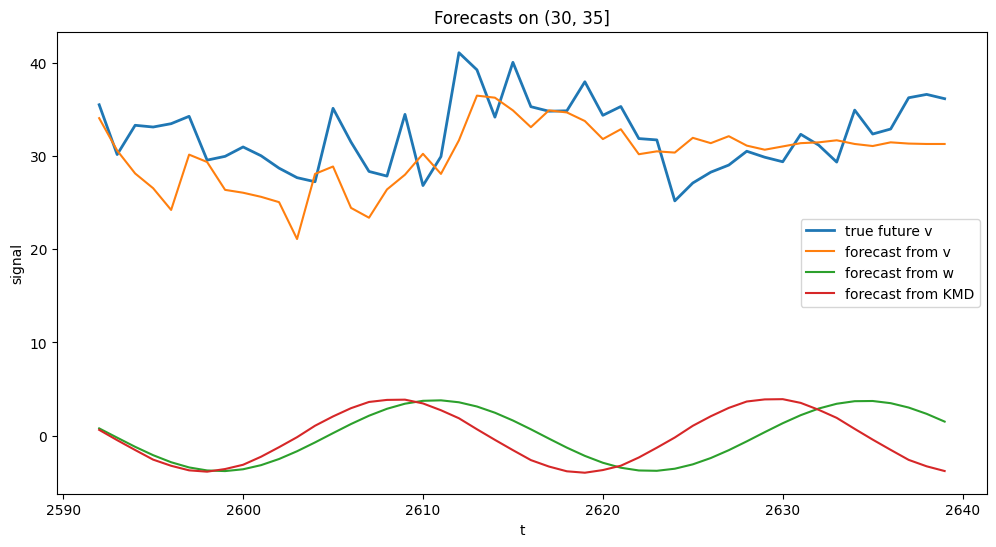

In [62]:
t_future = np.arange(n_train,n_train+horizon_steps)
plt.figure(figsize=(12, 6))
plt.plot(t_future[:h], v_test[:h], label="true future v", linewidth=2)
plt.plot(t_future[:h], pred_from_v[:h], label="forecast from v")
plt.plot(t_future[:h], pred_from_w[:h], label="forecast from w")
plt.plot(t_future[:h], pred_from_KMD[:h], label="forecast from KMD")
plt.legend()
plt.xlabel("t")
plt.ylabel("signal")
plt.title("Forecasts on (30, 35]")
plt.show()

Energy computation progress:
0% 8 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=21, tm_min=8, tm_sec=31, tm_wday=0, tm_yday=103, tm_isdst=1)
4% 8 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=21, tm_min=8, tm_sec=31, tm_wday=0, tm_yday=103, tm_isdst=1)
8% 8 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=21, tm_min=8, tm_sec=31, tm_wday=0, tm_yday=103, tm_isdst=1)
12% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=21, tm_min=8, tm_sec=31, tm_wday=0, tm_yday=103, tm_isdst=1)
15% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=21, tm_min=8, tm_sec=31, tm_wday=0, tm_yday=103, tm_isdst=1)
19% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=21, tm_min=8, tm_sec=31, tm_wday=0, tm_yday=103, tm_isdst=1)
23% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=21, tm_min=8, tm_sec=31, tm_wday=0, tm_yday=103, tm_isdst=1)
27% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=21, tm_min=

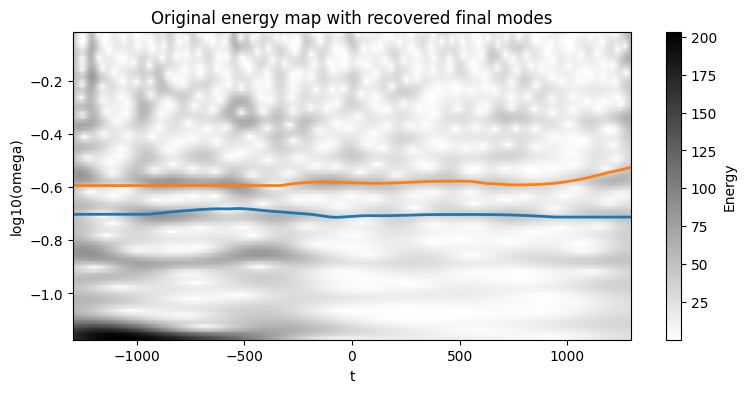

In [54]:
om_mesh = KMD_lib.make_omega_mesh(t_mesh, alpha)

E_original = KMD_lib.compute_E_fast(
    t_mesh,
    om_mesh,
    wp,
    signal,
    np.zeros((0, len(t_mesh), 4)),
    np.zeros((0, len(t_mesh), 2, 2)),
    0,
    alpha
)

plt.figure(figsize=(9, 4))
plt.imshow(
    E_original,
    cmap="gray_r",
    origin="lower",
    aspect="auto",
    extent=[t_mesh[0], t_mesh[-1], np.log10(om_mesh[0]), np.log10(om_mesh[-1])]
)

for mode_i in range(Comp_data_full.shape[0]):
    omega_i = Comp_data_full[mode_i, :, 2]
    nz = np.nonzero(omega_i)[0]
    if len(nz) > 0:
        plt.plot(t_mesh[nz], np.log10(omega_i[nz]), linewidth=2)

plt.colorbar(label="Energy")
plt.xlabel("t")
plt.ylabel("log10(omega)")
plt.title("Original energy map with recovered final modes")
plt.show()